An image is a collection of pixels, which is abbreviation for picture elements. (පින්තූරයක් (Image) යනු පික්සෙල් (pixels) සමූහයක එකතුවකි. "Pixel" යන වචනය නිර්මාණය වී ඇත්තේ "picture elements" (පින්තූරයක මූලද්‍රව්‍ය/කොටස්) යන වචන ද්විත්වය කෙටි කිරීමෙනි.)

Grayscale image (ග්‍රේස්කේල් රූපයක්) යනු කළු, සුදු සහ අළු (gray) වර්ණයේ විවිධ ඡායාවන් (shades) පමණක් භාවිත කරමින් නිර්මාණය වන පින්තූරයකි.

A grayscale image can be represented as a two dimensional array, whose first axis corresponds to the x coordinate of the image and the second axis corresponds to the y coordinate. The array contains at each coordinate pair (x,y) a value, which is typically a float between 0.0 and 1.0, or an integer between 0 and 255. This specifies the level of grayness. For example, if the array contains value 255 at coordinates (0,0), then in the image the pixel at top left is white.

In color images, each pixel has three color components (or channels) corresponding to red, green, and blue (RGB).

```
(0,1,0)   <-- Each one called color component or channel
  0 is a  color component / channel
  1 is a  color component / channel
  0 is a  color component / channel
```

These channels form the third axis of the image, with each channel storing a value that represents the intensity of the respective color. The channel value ranges between 0.0 and 1.0 (or between 0 and 255). By combining different intensity values for the red, green, and blue components of a pixel, it's possible to represent up to 16.7 million unique colors.

Since images can be represented as multidimensional arrays, we can easily process images using NumPy functions. Let's see examples of these.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

(618, 1080, 4)
The image consists of 667440 pixels


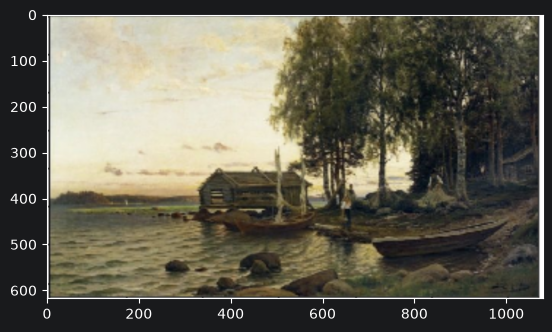

In [2]:
painting = plt.imread('images/painting.png') # This line reads an image file from disk and turns it into a NumPy array of pixel values — so you can then process it with NumPy (like the mirroring you just saw).
print(painting.shape)
print(f'The image consists of {painting.shape[0] * painting.shape[1]} pixels')
plt.imshow(painting)
plt.show()

## `plt.imread(...)` — Loading an Image Into a NumPy Array

This line **reads an image file from disk and turns it into a NumPy array** of pixel values — so you can then process it with NumPy (like the mirroring you just saw).

---

### What It Does

```python
painting = plt.imread('images/painting.png')
```

- **`plt.imread`** = "image read" — loads an image file
- **`'images/painting.png'`** = the path to the image file (in an `images` folder)
- **`painting`** = the result — a **NumPy array** holding every pixel's color values

So `painting` is no longer a "picture file" — it's an **array of numbers** representing the picture.

---

### `imread` vs `imshow` — The Pair

These two are opposites:

```python
painting = plt.imread('images/painting.png')    # READ: file  → array
plt.imshow(painting)                              # SHOW: array → displayed image
```

| Function | Direction | Does |
|---|---|---|
| `plt.imread` | file → array | **loads** an image into numbers |
| `plt.imshow` | array → screen | **displays** numbers as an image |

`imread` brings the image *in* as data; `imshow` puts data back *out* as a visible picture.

---

### What the Array Looks Like

An image becomes a grid of pixels. For a **color** image, each pixel has red, green, blue (and sometimes alpha/transparency) values:

```python
print(painting.shape)
# → (height, width, 3)     for RGB color
# → (height, width, 4)      for RGBA (with transparency) — common for .png
# → (height, width)          for grayscale
```

For example, `(600, 800, 3)` means: 600 pixels tall, 800 wide, 3 color values (R, G, B) per pixel.

```python
painting[0, 0]      # → the color of the TOP-LEFT pixel, e.g. [0.2, 0.5, 0.8]
```

---

### The Values — Usually 0 to 1 for PNG

For `.png` files, `imread` typically returns **float values between 0 and 1**:
- `0.0` = no intensity (dark)
- `1.0` = full intensity (bright)

So a pixel `[1.0, 0.0, 0.0]` is pure red. (Other formats like `.jpg` may give integers 0–255 instead.)

---

### Why Load an Image as an Array?

Because once it's a NumPy array, you can use **all your NumPy skills** on it:

```python
painting[:, ::-1]          # mirror it (what you just learned!)
painting[::-1, :]           # flip upside down
painting[100:300, 200:400]   # crop a region (slicing!)
painting * 0.5                # darken it (vectorized!)
painting[:, :, 0]              # extract just the red channel
```

Image processing becomes **array manipulation** — the slicing, vectorization, and indexing you've been learning all apply directly to pictures.

---

### The Typical Workflow

```python
import matplotlib.pyplot as plt

painting = plt.imread('images/painting.png')   # 1. load image → array
mirrored = painting[:, ::-1]                    # 2. process the array
plt.imshow(mirrored)                             # 3. display the result
plt.show()
```

Load → manipulate as numbers → display. That's the whole pattern of basic image processing.

---

### One Practical Note — The File Path

The path `'images/painting.png'` is **relative** to where your notebook/script runs (remember the relative-path idea from file I/O). If you get a `FileNotFoundError`, the `images` folder isn't where Python expects — check that `painting.png` actually sits in an `images` folder next to your notebook.

---

### The One-Sentence Summary

> `plt.imread('images/painting.png')` **loads an image file from disk into a NumPy array** of pixel values (shape like `(height, width, 3)` for color, with values usually `0`–`1` for PNGs), storing it in `painting`. It's the opposite of `plt.imshow` (which displays an array as an image) — and once the picture is an array, you can process it with all your NumPy tools: slicing to crop or mirror, vectorized math to brighten or darken, and indexing to pull out color channels. 🎯

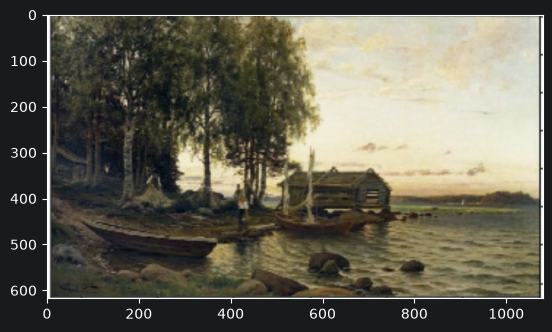

In [3]:
plt.imshow(painting[:,::-1])  # mirror the image in x direction

## `painting[:, ::-1]` — Mirroring an Image Horizontally

This flips an image **left-to-right** (a mirror image) using a slicing trick, then displays it. The magic is the `::-1` slice, which reverses along an axis. Let me break it down.

---

### First — What an Image Is in NumPy

An image is just a NumPy array where each element is a pixel. For a grayscale image, it's 2D (rows × columns); for color, 3D (rows × columns × color channels):

```
painting.shape = (height, width)          # grayscale
painting.shape = (height, width, 3)        # color (RGB)
```

- **rows** (axis 0) = top-to-bottom (the y-direction)
- **columns** (axis 1) = left-to-right (the x-direction)

---

### The Slice — `painting[:, ::-1]`

Recall the comma splits dimensions (from your slicing lessons):

```python
painting[ : , ::-1 ]
          │    │
          │    └── COLUMNS: ::-1 means "reverse" (left ↔ right)
          └─────── ROWS: ":" means "all rows, unchanged" (top stays top)
```

- **`:`** (rows) → keep all rows as they are (no vertical flip)
- **`::-1`** (columns) → **reverse the column order** → flips left-to-right

---

### What `::-1` Means — Reverse

`::-1` is the slice `start:stop:step` with a **step of -1**, which walks through backwards:

```python
a = [10, 20, 30, 40]
a[::-1]      # → [40, 30, 20, 10]   reversed!
```

```
::-1  →  start=blank (from the end), stop=blank (to the start), step=-1 (backwards)
      →  "go through everything in reverse order"
```

Applied to an image's **columns**, reversing them swaps left and right — the first column becomes the last, creating a horizontal mirror.

---

### Visualizing the Flip

```
Original columns:        Reversed columns (::-1):
col0 col1 col2 col3       col3 col2 col1 col0
 A    B    C    D          D    C    B    A      ← left/right swapped!
```

So a face looking left now looks right — a mirror image, like looking in a mirror.

```
Original:          Mirrored (painting[:, ::-1]):
┌─────────┐        ┌─────────┐
│  o   o  │        │  o   o  │
│    >    │   →    │    <    │   ← flipped horizontally
│  \___/  │        │  \___/  │
└─────────┘        └─────────┘
```

---

### `plt.imshow(...)` — Display the Image

```python
plt.imshow(painting[:, ::-1])
```

`imshow` ("image show") **displays** a NumPy array as an image. So this whole line: *"take the painting, reverse its columns (mirror left-right), and show the result."*

The `;` at the end just suppresses Jupyter's text output (so it shows only the image, not the object's repr).

---

### The Three Flip Directions — For Comparison

```python
painting[:, ::-1]     # mirror HORIZONTALLY (left ↔ right)  ← this one
painting[::-1, :]      # mirror VERTICALLY (top ↔ bottom)   — reverse ROWS
painting[::-1, ::-1]    # rotate 180° (both flipped)         — reverse both
```

```
[:, ::-1]   → reverse columns → left/right mirror
[::-1, :]   → reverse rows    → top/bottom mirror (upside down)
[::-1, ::-1]→ reverse both    → 180° rotation
```

The position of `::-1` (before or after the comma) decides which axis flips — same as the slicing logic you learned.

---

### Equivalent Built-in

NumPy also has a named function for this (from your "mirror a matrix" question!):

```python
painting[:, ::-1]      # slicing trick
np.fliplr(painting)     # same result — "flip left-right"
```

Both mirror horizontally; the slicing version is just more explicit about *how*.

---

### The One-Sentence Summary

> `painting[:, ::-1]` mirrors an image **left-to-right**: the `:` keeps all rows unchanged (no vertical flip), while `::-1` on the columns **reverses their order** (step of -1 = backwards), swapping left and right to create a mirror image. `plt.imshow(...)` then displays it — so the whole line shows the horizontally-flipped painting (equivalent to `np.fliplr(painting)`). 🎯

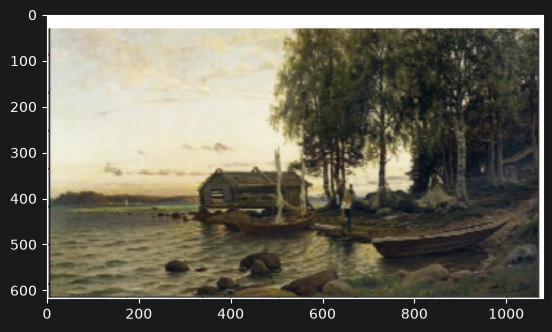

In [4]:
painting2 = painting.copy()
painting2[0:30,:,:] = 1.0
plt.imshow(painting2)

## Painting a White Stripe on a Copy — Simply

These two lines **make a safe copy** of the image, then **paint the top 30 rows white**. Two separate ideas: why copy, and how the slice-assignment paints.

---

### Line 1 — `painting2 = painting.copy()`

This creates a **brand-new, independent array** with the same pixels:

```python
painting2 = painting.copy()    # a separate copy — changes won't affect painting
```

**Why not just `painting2 = painting`?** Because that would NOT copy anything — it just makes a **second name pointing to the same array** (the name-as-label idea from earlier lessons):

```python
painting2 = painting           # ✗ same array, two names
painting2[0:30, :, :] = 1.0    # → painting is ALSO changed!

painting2 = painting.copy()    # ✓ independent array
painting2[0:30, :, :] = 1.0    # → painting stays untouched
```

That's what the comment means: *"don't mess the original painting!"* — `.copy()` protects the original.

---

### Line 2 — `painting2[0:30, :, :] = 1.0`

Break down the slice (three dimensions for a color image: rows, columns, channels):

```python
painting2[ 0:30 , : , : ] = 1.0
            │      │   │
            │      │   └── all color channels (R, G, B)
            │      └────── all columns (full width)
            └───────────── rows 0 to 29 (the top 30 rows)
```

So it selects **the top 30 rows, across the full width, in every color channel** — a horizontal stripe at the top — and sets every value there to `1.0`.

---

### Why `1.0` Makes White

For PNG images, each channel ranges from `0.0` (none) to `1.0` (full). A pixel's color is its **R, G, B** mix:

```
[1.0, 1.0, 1.0]  → full red + full green + full blue = WHITE
[0.0, 0.0, 0.0]  → nothing                          = BLACK
[1.0, 0.0, 0.0]  → full red only                    = RED
```

Setting **all three channels to 1.0** gives white — hence the comment *"max value for all three components produces white."*

---

### The Result

```
Before:                     After (painting2):
┌──────────────┐            ┌──────────────┐
│  painting    │            │██████████████│ ← top 30 rows now WHITE
│   image      │     →      │  painting    │
│              │            │   image      │
└──────────────┘            └──────────────┘
```

And `painting` (the original) is unchanged, thanks to `.copy()`.

---

### Assigning One Value to a Whole Slice — Broadcasting

Notice you assigned a **single number** (`1.0`) to a whole block of `30 × width × 3` values. NumPy **broadcasts** that scalar to every position in the slice — the same "scalar stretches to fill" rule you learned with `arr + 4`. No loop needed.

You could even paint a color stripe by assigning one RGB triple, which broadcasts across all those pixels:

```python
painting2[0:30, :, :] = [1.0, 0.0, 0.0]    # red stripe
```

---

### The One-Sentence Summary

> `painting.copy()` makes an **independent** copy so the original image isn't modified (plain `painting2 = painting` would just be a second name for the same array); then `painting2[0:30, :, :] = 1.0` selects the **top 30 rows, all columns, all color channels** and sets them to `1.0` — full red, green, and blue — which is **white**, with NumPy broadcasting that single value across the whole stripe. 🎯

For a bit more complicated operation we can create a function that returns a copy of the image so that it fades to black as we move to left.

In [6]:
def fadex(image):
    height, width = image.shape[:2]

    #image.shape      → (600, 800, 3)
    #image.shape[:2]  → (600, 800)   → height=600, width=800

    m=np.linspace(0,1,width).reshape(1,width,1)
    result =  image * m
    return result


(618, 1080, 4)


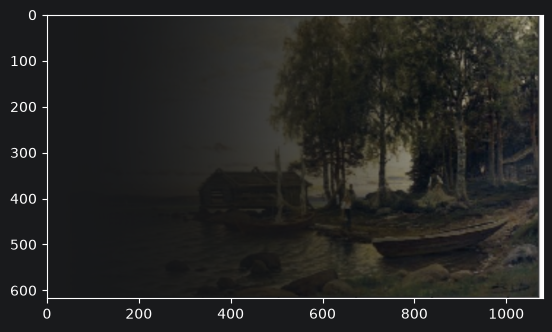

In [7]:
modified=fadex(painting)
print(modified.shape)
plt.imshow(modified)

## One Picture, Written as a Mathematical Matrix

Let's keep this to **one** clear view and then explain why the code looked different.

---

### Step 1 — The Picture Is a 3×4 Matrix of Pixels

The image has **3 rows** and **4 columns** of pixels. Write it as an ordinary matrix where **each entry is one pixel (one color)**:

```
        ┌                      ┐     ┌                                  ┐
        │ p00  p01  p02  p03   │     │ red     green   blue     white   │
    I = │ p10  p11  p12  p13   │  =  │ yellow  cyan    magenta  black   │
        │ p20  p21  p22  p23   │     │ grey    grey    orange   orange  │
        └                      ┘     └                                  ┘
```

- **Left:** the pixel *positions* — `p` followed by row number, then column number (`p12` = row 1, column 2).
- **Right:** the *color* at each position.

This matrix **is the table** — 3 rows, 4 columns, 12 pixels. Nothing else.

---

### Step 2 — Each Pixel Is 3 Numbers (R, G, B)

Each entry `pij` is not a single number — it's a color made of three amounts:

```
    pij = (R, G, B)
```

Now replace each color name with its three numbers:

```
        ┌                                                    ┐
        │ (1,0,0)       (0,1,0)       (0,0,1)    (1,1,1)     │   ← row 0
    I = │ (1,1,0)       (0,1,1)       (1,0,1)    (0,0,0)     │   ← row 1
        │ (.5,.5,.5)    (.5,.5,.5)    (1,.5,0)   (1,.5,0)    │   ← row 2
        └                                                    ┘
            col 0         col 1         col 2      col 3
```

That's the whole image: **a 3×4 matrix, where every entry is a triple (R, G, B)**.

```
    3 rows  ×  4 columns  ×  3 numbers per entry   →   shape (3, 4, 3)
```

---

### Step 3 — Why the Code Looked Like 4×3 Blocks

Here's the source of the confusion. Look at **row 0** of the matrix above:

```
    row 0 = ( (1,0,0),  (0,1,0),  (0,0,1),  (1,1,1) )
               red       green     blue      white
```

In the picture, these 4 pixels sit **side by side, left to right**. But in the code, each pixel was written on **its own line** so the comments fit:


```
import numpy as np

image = np.array([
    # row 0
    [[1.0, 0.0, 0.0],    # col 0: red
     [0.0, 1.0, 0.0],    # col 1: green
     [0.0, 0.0, 1.0],    # col 2: blue
     [1.0, 1.0, 1.0]],   # col 3: white

    # row 1
    [[1.0, 1.0, 0.0],    # col 0: yellow  (red + green)
     [0.0, 1.0, 1.0],    # col 1: cyan    (green + blue)
     [1.0, 0.0, 1.0],    # col 2: magenta (red + blue)
     [0.0, 0.0, 0.0]],   # col 3: black

    # row 2
    [[0.5, 0.5, 0.5],    # col 0: grey
     [0.5, 0.5, 0.5],    # col 1: grey
     [1.0, 0.5, 0.0],    # col 2: orange
     [1.0, 0.5, 0.0]],   # col 3: orange
])

print(image.shape)       # → (3, 4, 3)
```

```python
[[1.0, 0.0, 0.0],    # col 0  ← leftmost pixel
 [0.0, 1.0, 0.0],    # col 1
 [0.0, 0.0, 1.0],    # col 2
 [1.0, 1.0, 1.0]],   # col 3  ← rightmost pixel
```

Those 4 lines are **the same 4 pixels going left → right** — they're just typed vertically. So the "4×3 block" is really:

```
    4  ×  3
    │     └── R, G, B of each pixel
    └──────── 4 pixels across the row
```

It's **one image row, written sideways in the code**, not 4 rows of the picture.

```
In the picture (row 0):    red   green   blue   white      ← horizontal
In the code (row 0):       red                              ← same pixels,
                           green                               typed one
                           blue                                per line
                           white
```

---

### Putting It Together

| What you see | Mathematically |
|---|---|
| The whole picture | a **3×4** matrix of pixels |
| One entry of that matrix | one pixel = (R, G, B) |
| One code block like `[[...],[...],[...],[...]]` | **one image row**: its 4 pixels, each written on its own line |

---

### The One-Sentence Summary

> The image is simply a **3×4 matrix** (3 rows, 4 columns of pixels) — exactly the color table — where **each entry is a triple (R, G, B)**, giving shape `(3, 4, 3)`. The code only *looked* like 4×3 blocks because each image row's 4 pixels were typed **one per line** for readability; in the actual picture those 4 pixels sit side by side, left to right.

## The Fade, Step by Step as Matrices

### Step 0 — The Image

```
        ┌                                                    ┐
        │ (1,0,0)       (0,1,0)       (0,0,1)    (1,1,1)     │   ← row 0
    I = │ (1,1,0)       (0,1,1)       (1,0,1)    (0,0,0)     │   ← row 1
        │ (.5,.5,.5)    (.5,.5,.5)    (1,.5,0)   (1,.5,0)    │   ← row 2
        └                                                    ┘
            col 0         col 1         col 2      col 3

    shape (3, 4, 3)
```

---

### Step 1 — `np.linspace(0, 1, 4)`: One Weight per Column

```
    w = ( 0      .33      .67      1 )

    shape (4,)
```

---

### Step 2 — `.reshape(1, 4, 1)`: One Row, Four Columns, One Number Each

```
        ┌                                        ┐
    m = │ (0)       (.33)       (.67)       (1)  │   ← only 1 row
        └                                        ┘
          col 0     col 1       col 2       col 3

    shape (1, 4, 1)
```

Each entry holds **one** number (not three yet), and there is **one** row (not three yet).

---

### Step 3a — Broadcast the Channels: 1 Number → 3 Numbers

Each single weight is copied into all three slots (R, G, B):

```
        ┌                                                     ┐
    m = │ (0,0,0)     (.33,.33,.33)   (.67,.67,.67)   (1,1,1) │   ← still 1 row
        └                                                     ┘
          col 0       col 1           col 2           col 3

    shape (1, 4, 3)
```

---

### Step 3b — Broadcast the Rows: 1 Row → 3 Rows

The single row is reused for every image row:

```
        ┌                                                     ┐
        │ (0,0,0)     (.33,.33,.33)   (.67,.67,.67)   (1,1,1) │   ← row 0
    M = │ (0,0,0)     (.33,.33,.33)   (.67,.67,.67)   (1,1,1) │   ← row 1
        │ (0,0,0)     (.33,.33,.33)   (.67,.67,.67)   (1,1,1) │   ← row 2
        └                                                     ┘
          col 0       col 1           col 2           col 3

    shape (3, 4, 3)   ← same shape as I
```

Now every column has one weight, repeated down the rows and across R, G, B.

---

### Step 4 — Multiply Element by Element: `I * M`

Each number in `I` is multiplied by the number in the **same position** of `M` (written `⊙` = element-wise):

```
        ┌                                                    ┐
        │ (1,0,0)       (0,1,0)       (0,0,1)    (1,1,1)     │
        │ (1,1,0)       (0,1,1)       (1,0,1)    (0,0,0)     │
        │ (.5,.5,.5)    (.5,.5,.5)    (1,.5,0)   (1,.5,0)    │
        └                                                    ┘
                                  ⊙
        ┌                                                     ┐
        │ (0,0,0)     (.33,.33,.33)   (.67,.67,.67)   (1,1,1) │
        │ (0,0,0)     (.33,.33,.33)   (.67,.67,.67)   (1,1,1) │
        │ (0,0,0)     (.33,.33,.33)   (.67,.67,.67)   (1,1,1) │
        └                                                     ┘
```

One pixel worked out in full (row 1, col 2):

```
    (1, 0, 1)  ⊙  (.67, .67, .67)  =  (1×.67,  0×.67,  1×.67)  =  (.67, 0, .67)
     magenta                                                      darker magenta
```

---

### Step 5 — The Result

```
        ┌                                                        ┐
        │ (0,0,0)     (0,.33,0)        (0,0,.67)      (1,1,1)    │   ← row 0
    R = │ (0,0,0)     (0,.33,.33)      (.67,0,.67)    (0,0,0)    │   ← row 1
        │ (0,0,0)     (.17,.17,.17)    (.67,.33,0)    (1,.5,0)   │   ← row 2
        └                                                        ┘
          col 0       col 1            col 2          col 3
          ×0          ×.33             ×.67           ×1
          black       dark             half bright    unchanged
```

---

### The Whole Thing in One Line

```
    R[row, col, channel]  =  I[row, col, channel]  ×  w[col]
```

The weight depends **only on the column** — never on the row or the channel. That is exactly why `m` has shape `(1, 4, 1)`: the 4 sits in the column position, and the two 1s let it stretch over rows and channels.